# Deep learning for healthcare, session 5

**Is the model ready for clinical use? Risk, referral and reliability**

**Scenario:** a regional health service considers using our skin lesion network as a **triage aid**. Primary care staff photograph a lesion with a dermatoscope, a lit magnifying device; lesions the model scores as possibly cancerous are referred to a dermatologist. You sit on the review panel that recommends: deploy, restrict, study further, or stop

| Part | What we do | Approx. time |
|---|---|---|
| 1 | Are the risk numbers trustworthy? Calibration | 10 min |
| 2 | Choose a referral threshold and count the consequences | 10 min |
| 3 | Which cases should get direct specialist review? | 15 min |
| 4 | Robustness: blur, dark rooms, noise, colour casts | 10 min |
| 5 | Who does it miss? Subgroups | 10 min |
| 6 | Model card, regulation and the panel decision (protect this time) | 25 min |

**Words used in this notebook:** a **positive image** is one in the possibly cancerous group from session 3 (melanoma, basal cell carcinoma, actinic keratosis and very early skin cancer). Actinic keratosis is a pre-cancerous patch, so not every positive lesion is a cancer. **Sensitivity** is the share of positive images that trigger referral

**Responsible artificial intelligence (AI) questions today:** all five questions, ending with *who is accountable?*

Counts in this notebook refer to images, not necessarily distinct lesions or patients. Some lesions have more than one photo.

We report **area under the receiver operating characteristic curve (AUROC)** and **area under the precision-recall curve (AUPRC)** together. AUROC measures ranking across both classes. AUPRC focuses on finding positive images and depends on their share in the evaluated set. Here, AUPRC uses [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), rather than trapezoidal integration. Its no-skill reference is the share of positive images

## Setup

This notebook reuses the model saved in session 3. If it is missing, the next cells retrain it. Run time depends on the computer

### Prepare libraries and plots

We load the tools used throughout the notebook and set the random seed and plotting style so the examples run consistently.

In [1]:
# Setup: libraries, reproducibility, plot style
import warnings, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"

### Prepare image loading

We prepare helpers to load images, labels and lesion details consistently. They reuse local files and download missing ones so later cells can access the same data.

In [2]:
# Data: DermaMNIST (original and corrected) from the authors' public repository, cached in ./data
BASE = "https://raw.githubusercontent.com/kakumarabhishek/Corrected-Skin-Image-Datasets/main/DermaMNIST/DermaMNIST_Analysis/"
FILES = {"corrected": "NPZ_files/dermamnist_corrected_28.npz",
         "original": "NPZ_files/dermamnist_original.npz",
         "meta_corrected": "CSV_files/combined_metadata_corrected-HAM10000_corrected.csv",
         "split_original": "dermamnist_split_info.csv",
         "ham_meta": "HAM10000_metadata.csv"}
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
def fetch(key):
    path = DATA_DIR / Path(FILES[key]).name
    if not path.exists():
        print("downloading", path.name); urllib.request.urlretrieve(BASE + FILES[key], path)
    return path

CLASSES = {0: "Actinic keratosis (akiec)", 1: "Basal cell carcinoma (bcc)", 2: "Benign keratosis (bkl)",
           3: "Dermatofibroma (df)", 4: "Melanoma (mel)", 5: "Common mole (nv)", 6: "Vascular lesion (vasc)"}
# Actinic keratosis: a rough sun-damage patch that can turn into skin cancer; the group also includes very early skin cancer
CANCER_GROUP = [0, 1, 4]          # possibly cancerous: refer to a dermatologist

def load_split(key):
    d = np.load(fetch(key))
    return {s: {"X": d[f"{s}_images"], "cls": d[f"{s}_labels"].ravel(),
                "y": np.isin(d[f"{s}_labels"].ravel(), CANCER_GROUP).astype(np.float32)} for s in ["train", "val", "test"]}

def load_corrected_with_meta():
    data = load_split("corrected")
    meta = pd.read_csv(fetch("meta_corrected"))          # rows are in the same order as the images within each split
    for s in data:
        data[s]["meta"] = meta[meta.split == s].reset_index(drop=True)
    return data

### Define the network used in session 3

We recreate the network definition and helper functions from session 3 so its saved weights can run here. This cell defines the tools without training a model.

In [3]:
# A small convolutional neural network (CNN) and its training loop
class SmallCNN(nn.Module):
    """Three convolution blocks, then average over the image and one output neuron"""
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 28x28 -> 14x14
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 14x14 -> 7x7
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU())                   # 64 maps of 7x7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(X, mu, sd):
    """uint8 images (n, 28, 28, 3) -> normalised float tensor (n, 3, 28, 28)"""
    return torch.tensor(((X / 255.0 - mu) / sd).transpose(0, 3, 1, 2), dtype=torch.float32)

def augment(x):
    """Label-preserving changes for dermoscopy: mirror and rotate by 90 degree steps"""
    if np.random.rand() < 0.5: x = x.flip(3)
    if np.random.rand() < 0.5: x = x.flip(2)
    return torch.rot90(x, np.random.randint(4), (2, 3))

def predict_cnn(model, T, batch=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(T[i:i + batch])).numpy().ravel() for i in range(0, len(T), batch)])

def train_cnn(Xtr, ytr, Xva, yva, epochs=15, use_augment=True, seed=0, verbose=True):
    """Adam, batches of 128, keep the epoch with the best validation AUROC. Returns model, normalisation and history"""
    np.random.seed(seed); torch.manual_seed(seed)
    mu, sd = (Xtr / 255.0).mean((0, 1, 2)), (Xtr / 255.0).std((0, 1, 2))
    Ttr, Tva, yt = to_tensor(Xtr, mu, sd), to_tensor(Xva, mu, sd), torch.tensor(ytr)
    model = SmallCNN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); lossf = nn.BCEWithLogitsLoss()
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt)); tot = 0
        for i in range(0, len(yt), 128):
            b = perm[i:i + 128]; x = augment(Ttr[b]) if use_augment else Ttr[b]
            opt.zero_grad(); loss = lossf(model(x).squeeze(1), yt[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        pva = predict_cnn(model, Tva)
        auc = roc_auc_score(yva, pva)
        auprc = average_precision_score(yva, pva)
        hist.append({"epoch": ep + 1, "train_loss": tot / len(yt), "val_auroc": auc, "val_auprc": auprc})
        if auc > best: best, best_auprc, state = auc, auprc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()
    if verbose: print(f"trained {epochs} epochs in {time.time() - t0:.0f} s, selected validation AUROC {best:.3f}, AUPRC {best_auprc:.3f}")
    return model, (mu, sd), pd.DataFrame(hist)

### Load the model and predict scores

We load the saved model, or train it if missing, then predict scores for the risk and referral tests. This keeps the model fixed while we assess its proposed use.

In [4]:
# Load the session 3 model if it exists; otherwise retrain it with the same recipe (about 20 to 60 seconds)
data = load_corrected_with_meta()
CKPT = Path("models/cnn_corrected_seed0.pt")   # paths are relative: start Jupyter in the Deep_Learning_RAI folder
if CKPT.exists():
    ck = torch.load(CKPT, weights_only=False)
    model = SmallCNN(); model.load_state_dict(ck["state"]); model.eval(); mu, sd = ck["mu"], ck["sd"]
    print("loaded", CKPT)
else:
    model, (mu, sd), _ = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], seed=0)
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"state": model.state_dict(), "mu": mu, "sd": sd, "data": "dermamnist_corrected_28.npz", "seed": 0, "torch": torch.__version__}, CKPT)
T = {s: to_tensor(data[s]["X"], mu, sd) for s in data}
p = {s: predict_cnn(model, T[s]) for s in data}
y = {s: data[s]["y"] for s in data}
print({s: f"{len(y[s])} images, {int(y[s].sum())} possibly cancerous" for s in data})
print(f"Test AUROC {roc_auc_score(y['test'], p['test']):.3f}, AUPRC {average_precision_score(y['test'], p['test']):.3f}")

loaded models\cnn_corrected_seed0.pt


{'train': '8215 images, 1742 possibly cancerous', 'val': '573 images, 63 possibly cancerous', 'test': '1227 images, 149 possibly cancerous'}
Test AUROC 0.944, AUPRC 0.665


## 1. Do the predicted risks match the outcomes?

For images given a predicted probability of about 30%, about 30 in 100 should belong to the possibly cancerous group. This agreement between predictions and outcomes is called **calibration**

The groups differ across splits: about 21% of training images are positive, compared with 11% of validation images and 12% of test images. This can affect predicted risks, but does not by itself prove they are wrong

We fit **Platt scaling**, a logistic regression that adjusts the network's scores using validation images. We then check the adjusted predictions on test images

Source: [Scikit-learn guidance on probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

### Adjust the scores and check the probabilities

We fit a score adjustment using validation images, then compare test predictions with observed outcomes. This checks whether the adjusted numbers describe the frequency of positive images more accurately.

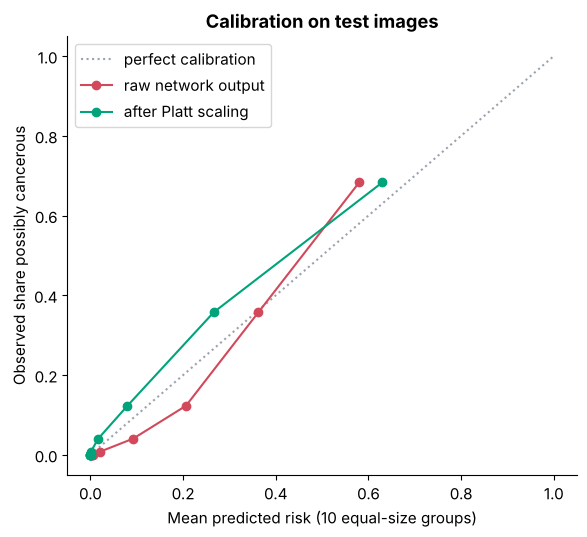

,mean predicted risk,observed share,Brier score
raw,0.128,0.121,0.062
calibrated,0.100,0.121,0.062


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
def logit(q): q = np.clip(q, 1e-6, 1 - 1e-6); return np.log(q / (1 - q)).reshape(-1, 1)
platt = LogisticRegression(C=1e6).fit(logit(p["val"]), y["val"])
pc = {s: platt.predict_proba(logit(p[s]))[:, 1] for s in p}          # calibrated risks

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], ":", color=GREY, label="perfect calibration")
for q, lab, c in [(p["test"], "raw network output", RED), (pc["test"], "after Platt scaling", GREEN)]:
    fp, mp = calibration_curve(y["test"], q, n_bins=10, strategy="quantile"); ax.plot(mp, fp, "o-", color=c, label=lab)
ax.set_xlabel("Mean predicted risk (10 equal-size groups)"); ax.set_ylabel("Observed share possibly cancerous")
ax.set_title("Calibration on test images"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({"mean predicted risk": [p["test"].mean(), pc["test"].mean()], "observed share": [y["test"].mean()] * 2,
                      "Brier score": [brier_score_loss(y["test"], p["test"]), brier_score_loss(y["test"], pc["test"])]},
                     index=["raw", "calibrated"]).round(3))

**What this shows** (plot and table above)

- Red shows raw predictions and green shows adjusted predictions, with the diagonal marking agreement between predictions and outcomes
- Calibration lowers average predicted risk from 12.8% to 10.0%, while both Brier scores round to 0.062
- [Validate calibration](https://scikit-learn.org/stable/modules/calibration.html) before interpreting scores as patient risks because the adjustment shows no improvement at the displayed precision
- Inspect referral-relevant score ranges because an acceptable average can hide substantial probability errors
- Collect more representative calibration data because the adjustment used only 63 positive validation images

## 2. Choose a referral rule and count the consequences

In our scenario, the service considers a missed positive image more harmful than an unnecessary referral. It asks for **at least 90% sensitivity**, meaning referral of at least 9 in 10 images in the possibly cancerous group

We choose the score threshold using validation images, then apply the same threshold to test images. Only 63 validation images are positive, so the chosen threshold may be unstable

### Set the threshold and test its stability

We choose a referral threshold using validation images, then count missed positives and referrals on test images. Repeating the selection with resampled lesions shows how stable that rule is.

,validation (where t was chosen),test (new images)
threshold,0.190,0.190
sensitivity,0.905,0.812
specificity,0.888,0.911
referrals per 100,19.895,17.685
positives missed,6.000,28.000
of positives,63.000,149.000
unnecessary referrals per positive found,1.000,0.793


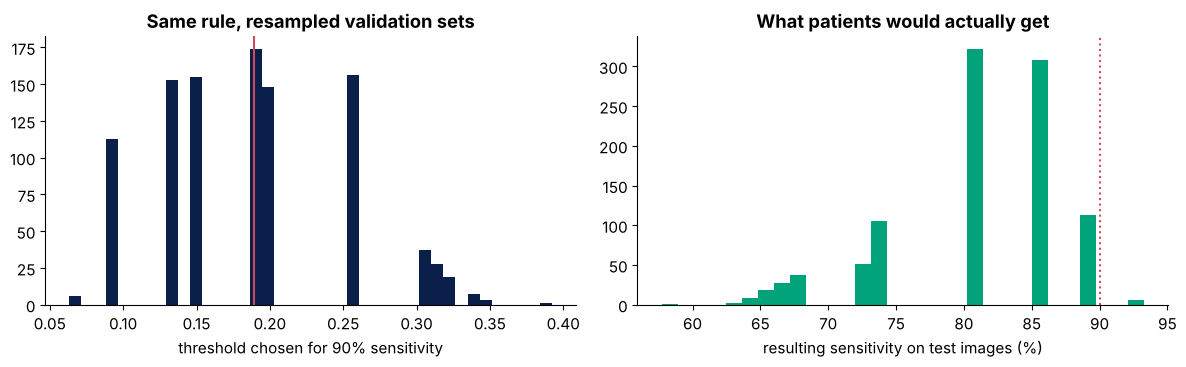

Test sensitivity across resampled thresholds: middle 95% from 66% to 89%, full range 58% to 93%


In [6]:
def threshold_for_sensitivity(yv, pv, target=0.90):
    return np.sort(pv[yv == 1])[int(np.floor((1 - target) * (yv == 1).sum()))]
t90 = threshold_for_sensitivity(y["val"], pc["val"])
def consequences(yv, pv, t):
    ref = pv >= t; pos = yv == 1
    return {"threshold": t, "sensitivity": ref[pos].mean(), "specificity": (~ref[~pos]).mean(),
            "referrals per 100": 100 * ref.mean(), "positives missed": int((~ref & pos).sum()), "of positives": int(pos.sum()),
            "unnecessary referrals per positive found": (ref & ~pos).sum() / max(1, (ref & pos).sum())}
display(pd.DataFrame({"validation (where t was chosen)": consequences(y["val"], pc["val"], t90),
                      "test (new images)": consequences(y["test"], pc["test"], t90)}).round(3))

# How stable is that threshold? Re-choose it on 1,000 resamples of the validation lesions (model, calibration and test set stay fixed)
rng = np.random.default_rng(0)
vles = data["val"]["meta"].lesion_id.values; vu = np.unique(vles); vrows = {g: np.where(vles == g)[0] for g in vu}
ts, sens = [], []
for _ in range(1000):
    b = np.concatenate([vrows[g] for g in rng.choice(vu, len(vu))])
    tb = threshold_for_sensitivity(y["val"][b], pc["val"][b]); ts.append(tb)
    sens.append((pc["test"][y["test"] == 1] >= tb).mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(ts, bins=40, color=NAVY); axes[0].axvline(t90, color=RED); axes[0].set_xlabel("threshold chosen for 90% sensitivity")
axes[0].set_title("Same rule, resampled validation sets")
axes[1].hist(100 * np.array(sens), bins=30, color=GREEN); axes[1].axvline(90, color=RED, ls=":")
axes[1].set_xlabel("resulting sensitivity on test images (%)"); axes[1].set_title("What patients would actually get")
plt.tight_layout(); plt.show()
print(f"Test sensitivity across resampled thresholds: middle 95% from {np.percentile(sens, 2.5):.0%} to {np.percentile(sens, 97.5):.0%}, full range {min(sens):.0%} to {max(sens):.0%}")

**What this shows** (table and plots above)

- The table applies one threshold to validation and test images; the histograms show how resampling changes thresholds and sensitivity
- Reassess the referral rule because it misses 28 of 149 positive images despite targeting 90% sensitivity
- Use more validation cases because threshold resampling changes sensitivity substantially while the model stays fixed
- Freeze a revised threshold on larger validation data, then test sensitivity and workload independently

## 3. Which cases should get direct specialist review?

We test whether an uncertainty estimate helps choose cases for review. **Monte Carlo dropout (MC dropout)** keeps dropout active during prediction, makes 50 predictions for the same image and measures how much they vary. It is an approximate uncertainty signal, not a guaranteed error range for that patient ([Gal and Ghahramani, 2016](https://arxiv.org/abs/1506.02142))

We simulate sending selected images directly to a dermatologist, even when the model would not refer them. We compare three selection rules

- Largest variation under MC dropout
- Scores closest to the referral threshold, measured on the model's internal score scale
- Random selection, for comparison

> **Simulation assumption:** the dermatologist correctly diagnoses every selected case. We count the extra reviews, but do not measure review time, waiting lists or diagnostic errors

### Compare three rules for specialist review

We compare sending uncertain cases, cases near the threshold or random cases directly to a dermatologist. We count missed positives and total reviews to see which rule uses specialist time best.

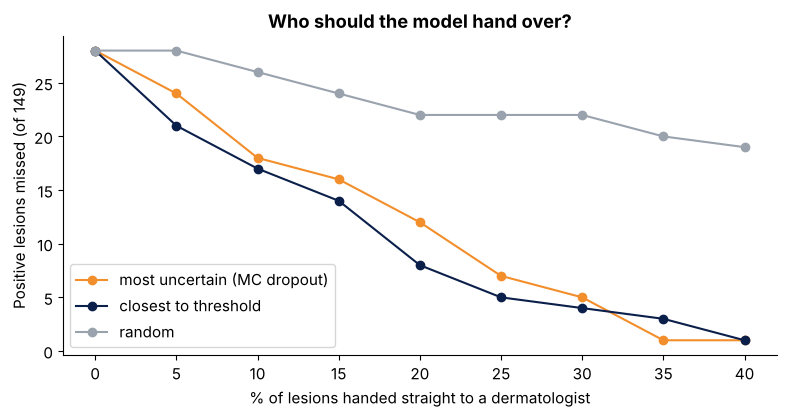

handed over %,0.0,5.0,10.0,15.0,20.0,25.0,30.0,35.0,40.0
most uncertain (MC dropout),28,24,18,16,12,7,5,1,1
closest to threshold,28,21,17,14,8,5,4,3,1
random,28,28,26,24,22,22,22,20,19


Total dermatologist reviews per 100 lesions (referrals plus hand-overs, each lesion counted once):


handed over %,0.0,5.0,10.0,15.0,20.0,25.0,30.0,35.0,40.0
most uncertain (MC dropout),17.7,20.5,22.7,24.9,27.6,30.4,32.9,36.1,40.1
closest to threshold,17.7,20.2,22.8,25.1,27.7,30.4,33.3,36.0,39.9
random,17.7,22.0,25.8,30.0,33.8,38.1,42.1,46.3,50.6


Correlation between MC dropout uncertainty and closeness to 0.5: 0.81


In [7]:
def mc_dropout(m, T_, passes=50):
    m.eval()
    for mod in m.modules():
        if isinstance(mod, nn.Dropout): mod.train()          # dropout on, batch normalisation stays fixed
    with torch.no_grad():
        out = np.stack([torch.sigmoid(m(T_)).numpy().ravel() for _ in range(passes)])
    m.eval(); return out.std(0)
unc = mc_dropout(model, T["test"])
yt, pt = y["test"], pc["test"]
logit_gap = np.abs(logit(pt).ravel() - logit(np.array([t90])).ravel())

fracs = np.arange(0, 0.41, 0.05)
def after_handover(order):
    rows = []
    for f in fracs:
        k = int(f * len(yt)); handed = np.zeros(len(yt), bool); handed[order[:k]] = True
        ref = (pt >= t90) & ~handed
        missed = int(((~ref) & (yt == 1) & ~handed).sum())
        rows.append({"handed over %": 100 * f, "positives missed": missed, "model referrals per 100": 100 * ref.mean(),
                     "total dermatologist reviews per 100": 100 * (ref | handed).mean()})
    return pd.DataFrame(rows)
orders = {"most uncertain (MC dropout)": np.argsort(-unc), "closest to threshold": np.argsort(logit_gap),
          "random": np.random.default_rng(0).permutation(len(yt))}
curves = {k: after_handover(o) for k, o in orders.items()}
fig, ax = plt.subplots(figsize=(8, 4.3))
for (k, c), col in zip(curves.items(), [ORANGE, NAVY, GREY]):
    ax.plot(c["handed over %"], c["positives missed"], "o-", color=col, label=k)
ax.set_xlabel("% of lesions handed straight to a dermatologist"); ax.set_ylabel(f"Positive lesions missed (of {int(yt.sum())})")
ax.set_title("Who should the model hand over?"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.concat({k: c.set_index("handed over %")["positives missed"] for k, c in curves.items()}, axis=1).T.astype(int))
print("Total dermatologist reviews per 100 lesions (referrals plus hand-overs, each lesion counted once):")
display(pd.concat({k: c.set_index("handed over %")["total dermatologist reviews per 100"] for k, c in curves.items()}, axis=1).T.round(1))
print(f"Correlation between MC dropout uncertainty and closeness to 0.5: {np.corrcoef(unc, -np.abs(p['test'] - 0.5))[0, 1]:.2f}")

**What this shows** (plot and table above)

- Curves show missed positives as more images receive direct specialist review, while tables also count total reviews
- At 20% handover, threshold-based selection misses eight positives, dropout misses twelve and random selection misses twenty-two
- Test reviewing 20% of cases near the threshold because it misses fewer positives than dropout at similar workloads
- Budget roughly six extra specialist reviews per additional positive image found in this simulation
- [Measure clinician accuracy](https://pubmed.ncbi.nlm.nih.gov/35585198/) and delays before claiming patient benefit because the simulation assumes perfect specialist diagnoses

## 4. Test changes in image quality

Clinical images can differ in blur, brightness, noise and colour balance. We simulate these changes at three levels and keep the same referral threshold

These are tests on small, altered images. The levels do not measure the range of conditions in a real primary care service

### Change image quality and repeat the assessment

We add blur, darkness, noise and warmer colours while keeping the referral threshold fixed. This checks how changing capture conditions affects ranking, missed positives, referrals and prediction variation.

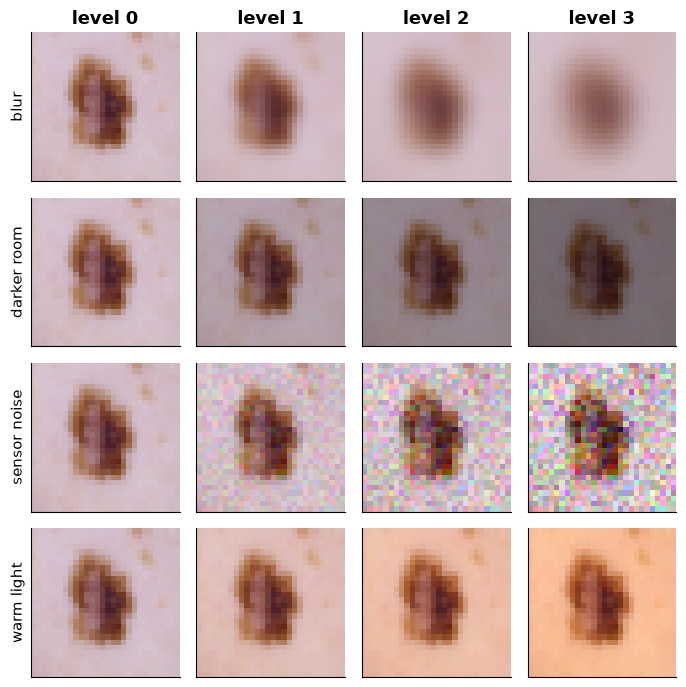

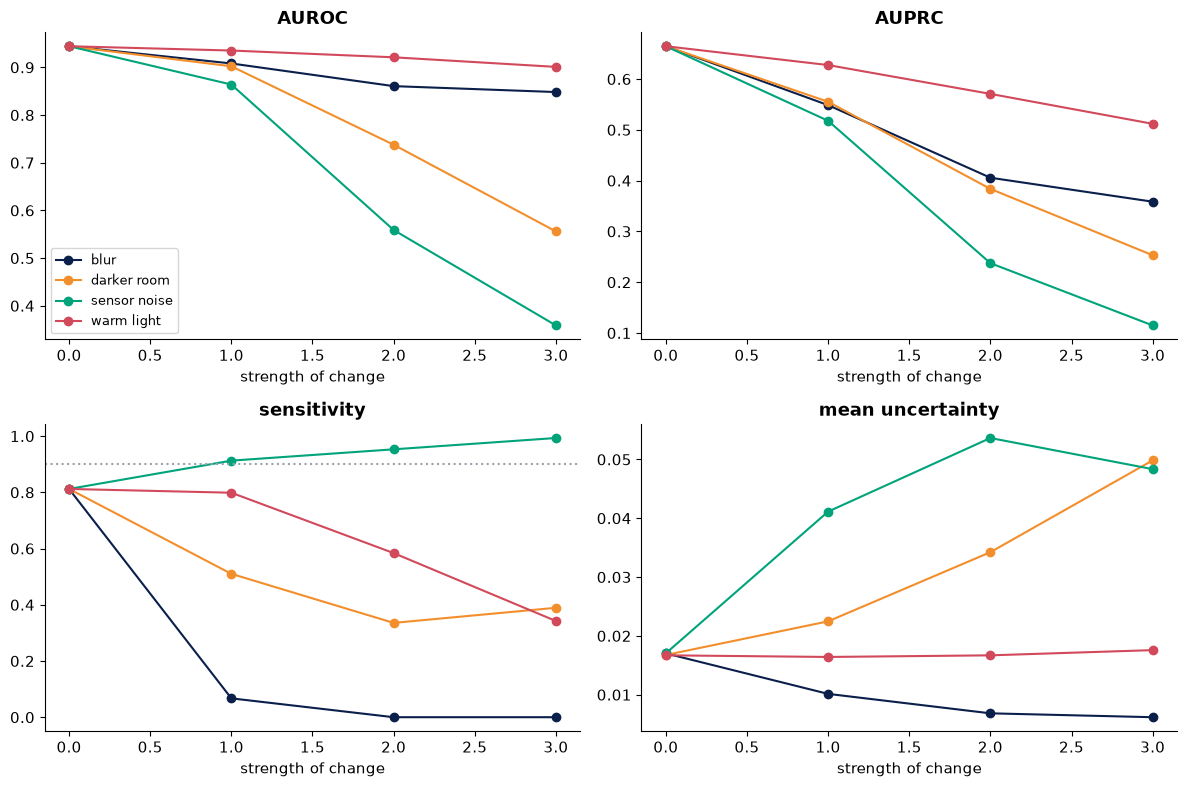

sensitivity                   referrals per 100                \
level                  0     1     2     3                 0      1      2   
change                                                                       
blur                0.81  0.07  0.00  0.00             17.77   0.98   0.00   
darker room         0.81  0.51  0.34  0.39             17.77  11.49   8.72   
sensor noise        0.81  0.91  0.95  0.99             17.77  46.94  94.30   
warm light          0.81  0.80  0.58  0.34             17.77  18.01  13.37   

                     
level             3  
change               
blur           0.00  
darker room   25.02  
sensor noise  98.53  
warm light     7.25

In [8]:
from scipy.ndimage import gaussian_filter
def corrupt(X, kind, level):
    Xf = X.astype(np.float32) / 255.0
    if kind == "blur": Xf = np.stack([gaussian_filter(im, sigma=(level, level, 0)) for im in Xf])
    if kind == "darker room": Xf = Xf * (1 - 0.15 * level)
    if kind == "sensor noise": Xf = Xf + np.random.default_rng(0).normal(0, 0.04 * level, Xf.shape)
    if kind == "warm light": Xf = Xf * np.array([1 + 0.06 * level, 1.0, 1 - 0.08 * level])
    return (np.clip(Xf, 0, 1) * 255).astype(np.uint8)
kinds = ["blur", "darker room", "sensor noise", "warm light"]
ex = data["test"]["X"][np.where(yt == 1)[0][5]]
fig, axes = plt.subplots(len(kinds), 4, figsize=(7, 7))
for r, k in enumerate(kinds):
    for c, lev in enumerate([0, 1, 2, 3]):
        axes[r, c].imshow(corrupt(ex[None], k, lev)[0] if lev else ex); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if c == 0: axes[r, c].set_ylabel(k)
        if r == 0: axes[r, c].set_title(f"level {lev}")
plt.tight_layout(); plt.show()

rows = []
for k in kinds:
    for lev in [0, 1, 2, 3]:
        Xc = data["test"]["X"] if lev == 0 else corrupt(data["test"]["X"], k, lev)
        Tc = to_tensor(Xc, mu, sd); q = platt.predict_proba(logit(predict_cnn(model, Tc)))[:, 1]
        rows.append({"change": k, "level": lev, "AUROC": roc_auc_score(yt, q), "AUPRC": average_precision_score(yt, q), "sensitivity": (q[yt == 1] >= t90).mean(),
                     "referrals per 100": 100 * (q >= t90).mean(), "mean uncertainty": mc_dropout(model, Tc, 20).mean()})
rob = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for k, col in zip(kinds, [NAVY, ORANGE, GREEN, RED]):
    d = rob[rob.change == k]
    for ax, met in zip(axes.ravel(), ["AUROC", "AUPRC", "sensitivity", "mean uncertainty"]):
        ax.plot(d.level, d[met], "o-", color=col, label=k); ax.set_title(met); ax.set_xlabel("strength of change")
axes[1, 0].axhline(0.9, color=GREY, ls=":"); axes[0, 0].legend(fontsize=9); plt.tight_layout(); plt.show()
display(rob.pivot(index="change", columns="level", values=["sensitivity", "referrals per 100"]).round(2))

**What this shows** (plots and table above)

- Panels track ranking, sensitivity and prediction variation as blur, darkness, noise or warmer colour increases
- Blur lowers sensitivity from about 81% to 7% at the first tested level, while prediction variation also falls
- Add an independent image-quality check because blur causes severe misses while prediction variation decreases
- Monitor referral workload because noisy images can send almost everyone for specialist review
- Test retaking poor images or requesting manual review using data from the intended cameras

## 5. Who does it miss?

We compare sensitivity across groups in the test images. Each estimate has a **95% confidence interval**, calculated with the Wilson method. Wider intervals mean less precise estimates, often because the group contains few positive images

The calculation treats images as independent. Some lesions have several photos, and patient identifiers are unavailable. These intervals may therefore understate uncertainty

### Compare missed cases and workload across groups

We compare sensitivity and referrals by sex, age, body site and source collection. The uncertainty intervals help us distinguish estimates needing more evidence from results that look precise.

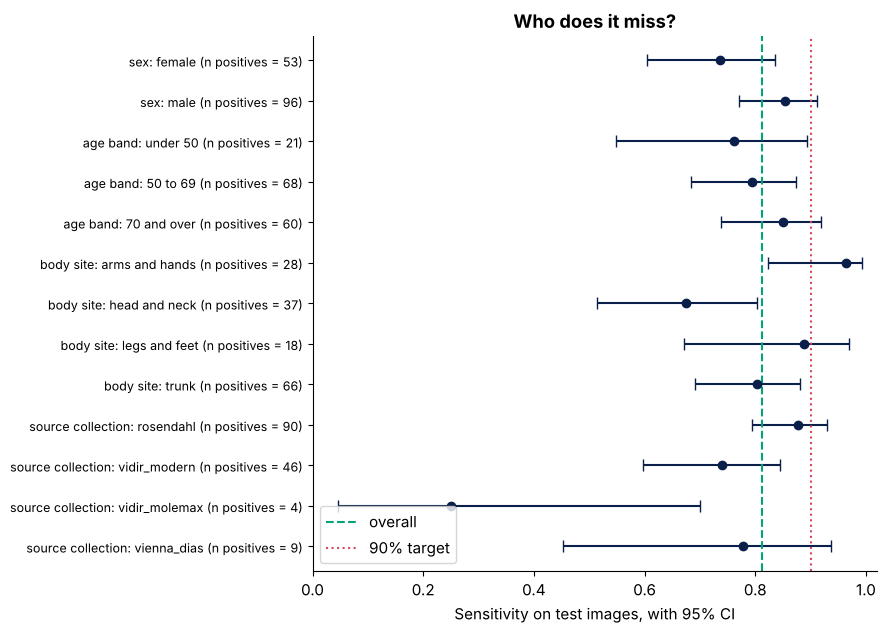

,attribute,group,images,positives,sensitivity,ci_low,ci_high,referrals per 100
0,sex,female,562,53,0.74,0.60,0.84,14.41
1,sex,male,656,96,0.85,0.77,0.91,20.58
2,age band,under 50,525,21,0.76,0.55,0.89,7.62
3,age band,50 to 69,481,68,0.79,0.68,0.87,19.33
4,age band,70 and over,210,60,0.85,0.74,0.92,39.52
5,body site,arms and hands,138,28,0.96,0.82,0.99,23.19
6,body site,head and neck,100,37,0.68,0.51,0.80,43.00
7,body site,legs and feet,270,18,0.89,0.67,0.97,10.00
8,body site,trunk,673,66,0.80,0.69,0.88,16.05
9,source collection,rosendahl,214,90,0.88,0.79,0.93,58.41


In [9]:
def wilson(k, n_, z=1.96):
    # Wilson 95% confidence interval for a proportion k / n_
    ph = k / n_; d = 1 + z**2 / n_; c = (ph + z**2 / (2 * n_)) / d; h = z * np.sqrt(ph * (1 - ph) / n_ + z**2 / (4 * n_**2)) / d
    return c - h, c + h
mt = data["test"]["meta"].copy()
mt["age band"] = pd.cut(mt.age, [-1, 49, 69, 120], labels=["under 50", "50 to 69", "70 and over"])
site_map = {"back": "trunk", "trunk": "trunk", "abdomen": "trunk", "chest": "trunk", "lower extremity": "legs and feet", "foot": "legs and feet",
            "upper extremity": "arms and hands", "hand": "arms and hands", "face": "head and neck", "scalp": "head and neck", "neck": "head and neck", "ear": "head and neck"}
mt["body site"] = mt.localization.map(site_map).fillna("other or unknown")
mt["source collection"] = mt.dataset
ref = pt >= t90
rows = []
for col in ["sex", "age band", "body site", "source collection"]:
    for g, idx in mt.groupby(col, observed=True).groups.items():
        idx = np.array(list(idx)); pos = idx[yt[idx] == 1]
        if len(pos) == 0: continue
        lo, hi = wilson(ref[pos].sum(), len(pos))
        rows.append({"attribute": col, "group": g, "images": len(idx), "positives": len(pos),
                     "sensitivity": ref[pos].mean(), "ci_low": lo, "ci_high": hi, "referrals per 100": 100 * ref[idx].mean()})
sg = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(sg) + 1))
ypos = np.arange(len(sg))[::-1]
ax.errorbar(sg.sensitivity, ypos, xerr=[sg.sensitivity - sg.ci_low, sg.ci_high - sg.sensitivity], fmt="o", color=NAVY, capsize=4)
ax.set_yticks(ypos); ax.set_yticklabels([f"{a}: {g} (n positives = {c})" for a, g, c in zip(sg.attribute, sg.group, sg.positives)], fontsize=9)
ax.axvline((pt[yt == 1] >= t90).mean(), color=GREEN, ls="--", label="overall")
ax.axvline(0.9, color=RED, ls=":", label="90% target"); ax.set_xlim(0, 1.02)
ax.set_xlabel("Sensitivity on test images, with 95% CI"); ax.set_title("Who does it miss?"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
display(sg.round(2))

**What this shows** (plot and table above)

- Dots show subgroup sensitivity, horizontal lines show uncertainty, and vertical reference lines mark overall sensitivity and the 90% target
- Head and neck sensitivity is 68%, despite 43 referrals per 100 images in that group
- Prioritise head and neck validation because high referral workload still misses about one third of positive images
- Estimate sex differences with appropriate uncertainty before changing thresholds for different groups
- Collect more positive cases and skin-tone data before claiming comparable performance across groups
- Account for repeated lesion images when estimating subgroup uncertainty

## 6. From evidence to a decision

### 6.1 A model card, filled from this notebook

A **model card** summarises a model's intended use, data, performance and limits ([Mitchell et al., 2019](https://arxiv.org/abs/1810.03993))

The next cell collects our results in one model card so reviewers can assess intended use, performance and limits together. Counts refer to images, which may include repeated photos of a lesion

In [10]:
tst = consequences(yt, pt, t90)
worst = sg.sort_values("sensitivity").iloc[0]
blur3 = rob[(rob.change == "blur") & (rob.level == 3)].iloc[0]
card = f'''
| Section | Content |
|---|---|
| **Intended use** | Triage aid: flags dermatoscope images of skin lesions as possibly cancerous (melanoma, basal cell carcinoma, actinic keratosis) for dermatologist review. Not a diagnosis |
| **Intended users** | Trained primary care staff with a dermatoscope; the final decision stays with a clinician |
| **Out of scope** | Phone photos without a dermatoscope; skin types not represented in the data; children; non-pigmented lesions outside these seven diagnoses |
| **Data** | DermaMNIST corrected, 28 x 28 pixels, from HAM10000 (Vienna and Queensland collections); split by lesion; no skin tone recorded |
| **Model** | Small convolutional network, {sum(q.numel() for q in model.parameters()):,} parameters, Platt-scaled on {len(y["val"])} validation images |
| **Discrimination** | Test AUROC {roc_auc_score(yt, pt):.3f}, AUPRC {average_precision_score(yt, pt):.3f} on {len(yt)} images ({int(yt.sum())} possibly cancerous) |
| **Operating point** | Threshold {t90:.3f}, set on validation for 90% sensitivity. Test: sensitivity {tst["sensitivity"]:.0%}, specificity {tst["specificity"]:.0%}, {tst["referrals per 100"]:.0f} referrals per 100, {tst["positives missed"]} of {tst["of positives"]} positive lesions missed |
| **Threshold stability** | Re-choosing the threshold on resampled validation sets gives test sensitivity from {np.percentile(sens, 2.5):.0%} to {np.percentile(sens, 97.5):.0%} |
| **Weakest subgroup found** | {worst.attribute} = {worst.group}: sensitivity {worst.sensitivity:.0%} (95% CI {worst.ci_low:.0%} to {worst.ci_high:.0%}, {int(worst.positives)} positive lesions) |
| **Robustness** | Strong blur: sensitivity {blur3.sensitivity:.0%}; see section 4 for other changes |
| **Known risks** | Shortcut learning from skin marks (session 4); performance depends on case mix (session 3); unknown performance on darker skin |
| **Human oversight (proposed)** | Borderline lesions handed to a dermatologist; clinicians can override; every output logged with model version. Owner and stopping rule still to be named |
| **Monitoring (proposed)** | Track referral rate and image quality monthly. Sensitivity needs follow-up of **non-referred** lesions too (for example a sample reviewed by a dermatologist, or later diagnoses from records), otherwise missed positives stay invisible. Re-check after any camera or protocol change. Cybersecurity not assessed |
'''
display(Markdown(card))


| Section | Content |
|---|---|
| **Intended use** | Triage aid: flags dermatoscope images of skin lesions as possibly cancerous (melanoma, basal cell carcinoma, actinic keratosis) for dermatologist review. Not a diagnosis |
| **Intended users** | Trained primary care staff with a dermatoscope; the final decision stays with a clinician |
| **Out of scope** | Phone photos without a dermatoscope; skin types not represented in the data; children; non-pigmented lesions outside these seven diagnoses |
| **Data** | DermaMNIST corrected, 28 x 28 pixels, from HAM10000 (Vienna and Queensland collections); split by lesion; no skin tone recorded |
| **Model** | Small convolutional network, 23,873 parameters, Platt-scaled on 573 validation images |
| **Discrimination** | Test AUROC 0.944, AUPRC 0.665 on 1227 images (149 possibly cancerous) |
| **Operating point** | Threshold 0.187, set on validation for 90% sensitivity. Test: sensitivity 81%, specificity 91%, 18 referrals per 100, 28 of 149 positive lesions missed |
| **Threshold stability** | Re-choosing the threshold on resampled validation sets gives test sensitivity from 64% to 89% |
| **Weakest subgroup found** | source collection = vidir_molemax: sensitivity 25% (95% CI 5% to 70%, 4 positive lesions) |
| **Robustness** | Strong blur: sensitivity 0%; see section 4 for other changes |
| **Known risks** | Shortcut learning from skin marks (session 4); performance depends on case mix (session 3); unknown performance on darker skin |
| **Human oversight (proposed)** | Borderline lesions handed to a dermatologist; clinicians can override; every output logged with model version. Owner and stopping rule still to be named |
| **Monitoring (proposed)** | Track referral rate and image quality monthly. Sensitivity needs follow-up of **non-referred** lesions too (for example a sample reviewed by a dermatologist, or later diagnoses from records), otherwise missed positives stay invisible. Re-check after any camera or protocol change. Cybersecurity not assessed |


### 6.2 What the regulation asks, in plain terms

In the **European Union (EU)**, software intended to inform diagnostic decisions generally falls under the **Medical Device Regulation (MDR)**. Rule 11 places such software in class IIa or higher, depending on the possible harm from a wrong decision. These classes require review by an authorised independent organisation, called a **notified body**

When an AI system is such a device or its safety component and requires that review, it meets the product-based high-risk conditions in the **Artificial Intelligence Act (AI Act)**. The exact classification depends on its intended use

| AI Act article | What it asks | Evidence from our five sessions | Gap |
|---|---|---|---|
| Art. 10 Data and data governance | Relevant, representative data; examine possible biases | Data audit, case mix (session 3) | No skin tone data |
| Art. 13 Transparency and information to deployers | Clear instructions: purpose, accuracy, limits, conditions of use | Model card above | Needs testing with real users |
| Art. 14 Human oversight | People can understand limits, avoid over-reliance, override or stop | Hand-over rule, explanation checks (sessions 4 and 5) | Review time and service capacity not measured |
| Art. 15 Accuracy, robustness and cybersecurity | Declared accuracy; resilience to errors and changing conditions | Robustness tests (section 4) | Only simulated changes; cybersecurity not tested |
| Art. 72 Post-market monitoring | Collect and analyse performance after deployment | Proposed monitoring plan in the model card | Needs follow-up of referred **and** non-referred lesions |

**Dates, checked for November 2026:** the AI Act entered into force on 1 August 2024. Regulation (EU) 2026/1744 took effect on 27 July 2026. It moved the main high-risk requirements in Chapter III, Sections 1 to 3, to 2 August 2028 for regulated-product systems under Article 6(1) and Annex I, including relevant medical devices, and to 2 December 2027 for uses listed in Article 6(2) and Annex III. Other provisions have their own application dates

Sources: [MDR, Annex VIII, Rule 11](https://eur-lex.europa.eu/eli/reg/2017/745/oj), [AI Act](https://eur-lex.europa.eu/eli/reg/2024/1689/oj), [2026 amendment, Article 1(40)](https://eur-lex.europa.eu/eli/reg/2026/1744/oj)

**Reporting:** follow the [2024 guideline for reporting clinical prediction models using regression or machine learning](https://doi.org/10.1136/bmj-2023-078378)

> These examples help us discuss regulatory requirements. Classroom experiments do not establish compliance or clinical safety

### 6.3 The review panel

Form groups of four. Each person takes one role and reads the evidence in this notebook through that lens

| Role | Main concern | Start from |
|---|---|---|
| Dermatologist | Missed positive lesions and unnecessary referrals | Sections 2 and 3 |
| Patient representative | Fairness, explanation, right to a second opinion | Section 5 and session 4 |
| Health service manager | Workload, cost, waiting lists | Referrals per 100, hand-over rate |
| Regulator or auditor | Evidence quality, documentation, monitoring | Model card and section 6.2 |

**Choose one recommendation**

- Deploy as proposed
- Deploy with specified restrictions
- Run a prospective study first: collect new cases in the intended service and assess outcomes
- Stop development for this use

Write down: your decision, the **two numbers** from this notebook that drove it, and the **one piece of missing evidence** that would most change your mind

## Course wrap-up: the five questions across five sessions

| Question | Intensive care network (sessions 1 and 2) | Skin lesion network (sessions 3 to 5) |
|---|---|---|
| What does it use? | Spread across thousands of weights; summaries hide trajectories | Data audit, explanation maps, a planted shortcut |
| How sure is it? | Five seeds, different patients flagged | Calibration, unstable threshold, Monte Carlo dropout |
| Who does it miss? | Different review lists between models | Some groups have few positive images; skin tone is unrecorded |
| Can we explain it accurately? | Input replacement tests answer limited questions | Maps answer different questions and need several checks |
| Who is accountable? | Version every model behind every alert | Model card, human oversight, post-market monitoring |

**Key insights**

- The image network improved on its pixel baseline. The intensive care network showed no clear gain that justified its extra complexity
- Clinical use needs evidence about risk estimates, referral decisions, specialist workload and performance under changed conditions
- Missing information, such as skin tone, limits what can be claimed and belongs in the model card

**Common pitfalls**

- Treating a validation score as proof of safety in a new setting
- Assuming a threshold chosen on a small sample will meet its target on new cases
- Assuming uncertainty estimates are guarantees for an individual patient

**Practical action:** require evidence for each question before clinical use, and name who will review outputs, monitor harm and stop the system if needed